# Computer Vision Lab 08: Object Detection using R-CNN, Fast R-CNN & Faster R-CNN

**Institution:** National University of Computer & Emerging Sciences (FAST-NUCES), Karachi  
**Department:** Department of Artificial Intelligence  
**Course:** Computer Vision (AI-4002)  
**Student Name:** Muhammad John Raza  
**Roll Number:** 23k-0069  
**Course Instructor:** Talha Shahid  

---

## Lab Overview & Objectives
In this laboratory, we implement end-to-end **Object Detection using Regional Convolutional Neural Networks (R-CNN)** on an Autonomous Driving and Traffic Scene dataset (`Car`, `Pedestrian`, `Traffic_Sign`).

### Key Modules:
1. **R-CNN Architectural Workflow:** Region Proposal generation, region warping, CNN feature extraction, classification, and bounding box regression.
2. **Data Exploration & Bounding Box Inspection:** Annotations parsing, class distributions, and ground-truth bounding box visualization.
3. **Selective Search & IoU Matching:** Graph-based hierarchical segmentation for region proposals, IoU matching for positive/negative sample harvesting.
4. **Multi-Task CNN Training:** Transfer learning using a deep convolutional backbone (ResNet18) trained with joint Classification (Cross-Entropy) and Bounding Box Regression (Smooth L1) loss.
5. **Inference with Non-Maximum Suppression (NMS):** Test image evaluation, proposal decoding, and NMS filtering.
6. **Architectural Comparison Summary:** In-depth evaluation of standard CNN, R-CNN, Fast R-CNN, and Faster R-CNN.


## 0. Environment Setup and Library Imports

In [1]:
import os
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torchvision
from IPython.display import Image, display

print(f"PyTorch Version:     {torch.__version__}")
print(f"Torchvision Version: {torchvision.__version__}")
print(f"OpenCV Version:      {cv2.__version__}")
print(f"Device:              {'CUDA' if torch.cuda.is_available() else 'CPU'}")


PyTorch Version:     2.11.0+cpu
Torchvision Version: 0.26.0+cpu
OpenCV Version:      5.1.0
Device:              CPU


---
## 1. Region-Based Convolutional Neural Networks (R-CNN Family)

### 1.1 R-CNN (Region-Based CNN)
R-CNN (Girshick et al., 2014) introduced deep learning to object detection via a three-stage pipeline:
$$\text{Input Image} \longrightarrow \text{Selective Search (}\sim 2000\text{ RoIs)} \longrightarrow \text{Affine Warp (224}\times 224\text{)} \longrightarrow \text{ConvNet Features} \longrightarrow \text{SVM Classifier + BBox Regressor}$$

**Workflow:**
1. **Region Proposals:** Selective Search groups pixels based on color, texture, size, and shape compatibility to propose $\sim 2000$ candidate bounding boxes.
2. **Feature Extraction:** Each candidate region is cropped, warped to a fixed dimension ($224 \times 224$), and independently passed through a CNN to extract a 4096-dimensional feature vector.
3. **Classification & Regression:** A linear SVM classifies each region into object classes vs. background, and a class-specific bounding box regressor refines coordinates.

### 1.2 Fast R-CNN
Fast R-CNN (Girshick, 2015) solves the huge computational redundancy of R-CNN:
$$\text{Input Image} \longrightarrow \text{Single ConvNet Pass} \longrightarrow \text{Feature Map} \longrightarrow \text{RoI Pooling} \longrightarrow \text{Fully-Connected Layers} \longrightarrow \text{Softmax + BBox Regressor}$$
- The entire image is passed through the ConvNet **only once** to generate a shared convolutional feature map.
- **RoI Pooling:** Projects each proposal onto the feature map and extracts a fixed-size $7 \times 7$ feature vector.
- Single-stage training with a joint multi-task loss.

### 1.3 Faster R-CNN
Faster R-CNN (Ren et al., 2015) eliminates the external Selective Search CPU bottleneck by introducing the **Region Proposal Network (RPN)**:
$$\text{Input Image} \longrightarrow \text{Shared Conv Layers} \longrightarrow \text{RPN generates candidate anchors} \longrightarrow \text{RoI Pooling} \longrightarrow \text{Detection Head}$$
- **Anchor Boxes:** RPN evaluates multi-scale, multi-aspect-ratio sliding anchors directly on feature maps.
- Feature maps are shared entirely between the proposal network and detection head, achieving **near real-time frame rates (5-10 FPS, 0.2s per image)**.


---
## 2. Dataset Exploration & Inspection (Traffic Object Detection)

We use an Autonomous Driving and Traffic Scene dataset containing ground-truth annotations for **`Car`**, **`Pedestrian`**, and **`Traffic_Sign`**.


      LAB 08 - TASK 0: DATA EXPLORATION & ANNOTATION INSPECTION  
      Author: Muhammad John Raza (23k-0069)                     

[*] First 5 rows of annotations (train.head()):
  image_names     cell_type  xmin  xmax  ymin  ymax
0       1.jpg  Traffic_Sign   204   238   147   184
1       1.jpg    Pedestrian   156   189   218   294
2       1.jpg           Car    85   229   281   368
3       2.jpg  Traffic_Sign   144   178   136   173
4       2.jpg    Pedestrian   142   172   222   292

[*] Total Bounding Box Annotations: 124
[*] Number of unique training images: 30

[*] Class Distribution (value_counts):
cell_type
Car             49
Pedestrian      45
Traffic_Sign    30



[*] Saved ground-truth visualization to outputs\data_exploration_gt.png


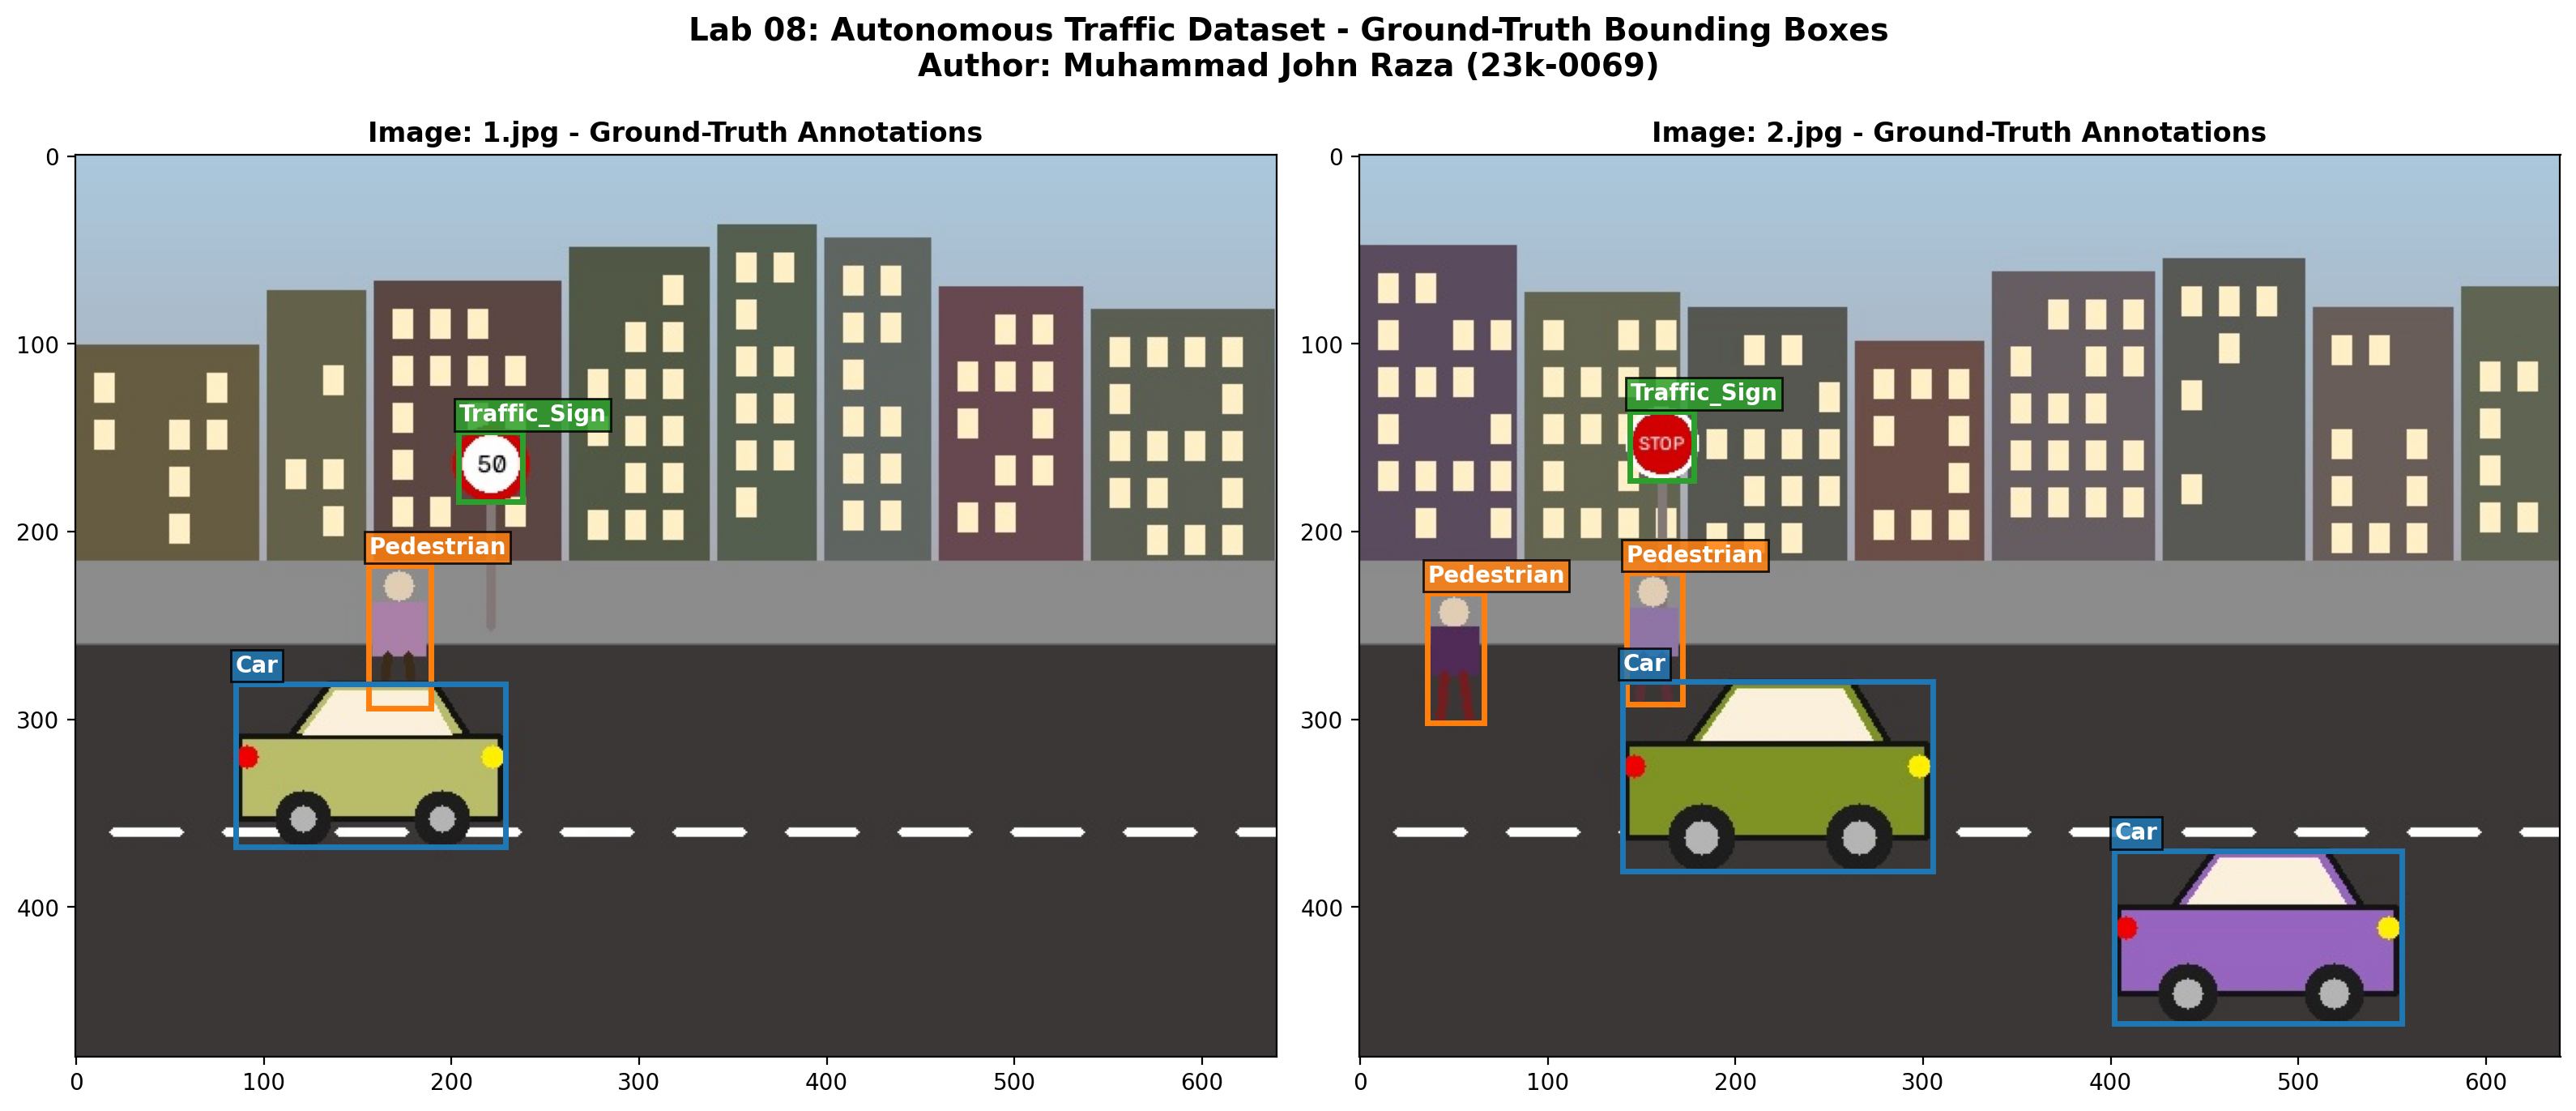

In [2]:
import task0_data_exploration as t0

gt_fig = t0.explore_data()
display(Image(filename=gt_fig))


---
## 3. Selective Search Region Proposals & IoU Matching

### Mathematical Formulation of Intersection-over-Union (IoU):
$$\text{IoU}(A, B) = \frac{\text{Area}(A \cap B)}{\text{Area}(A \cup B)} = \frac{\text{Area}(A \cap B)}{\text{Area}(A) + \text{Area}(B) - \text{Area}(A \cap B)}$$

**Sample Harvesting Protocol:**
- **Positive Foreground Samples:** Candidate regions with $\text{IoU} \ge 0.50$ matched to a ground-truth object.
- **Negative Background Samples:** Candidate regions with $\text{IoU} < 0.15$, capturing background road, sky, and building patches.


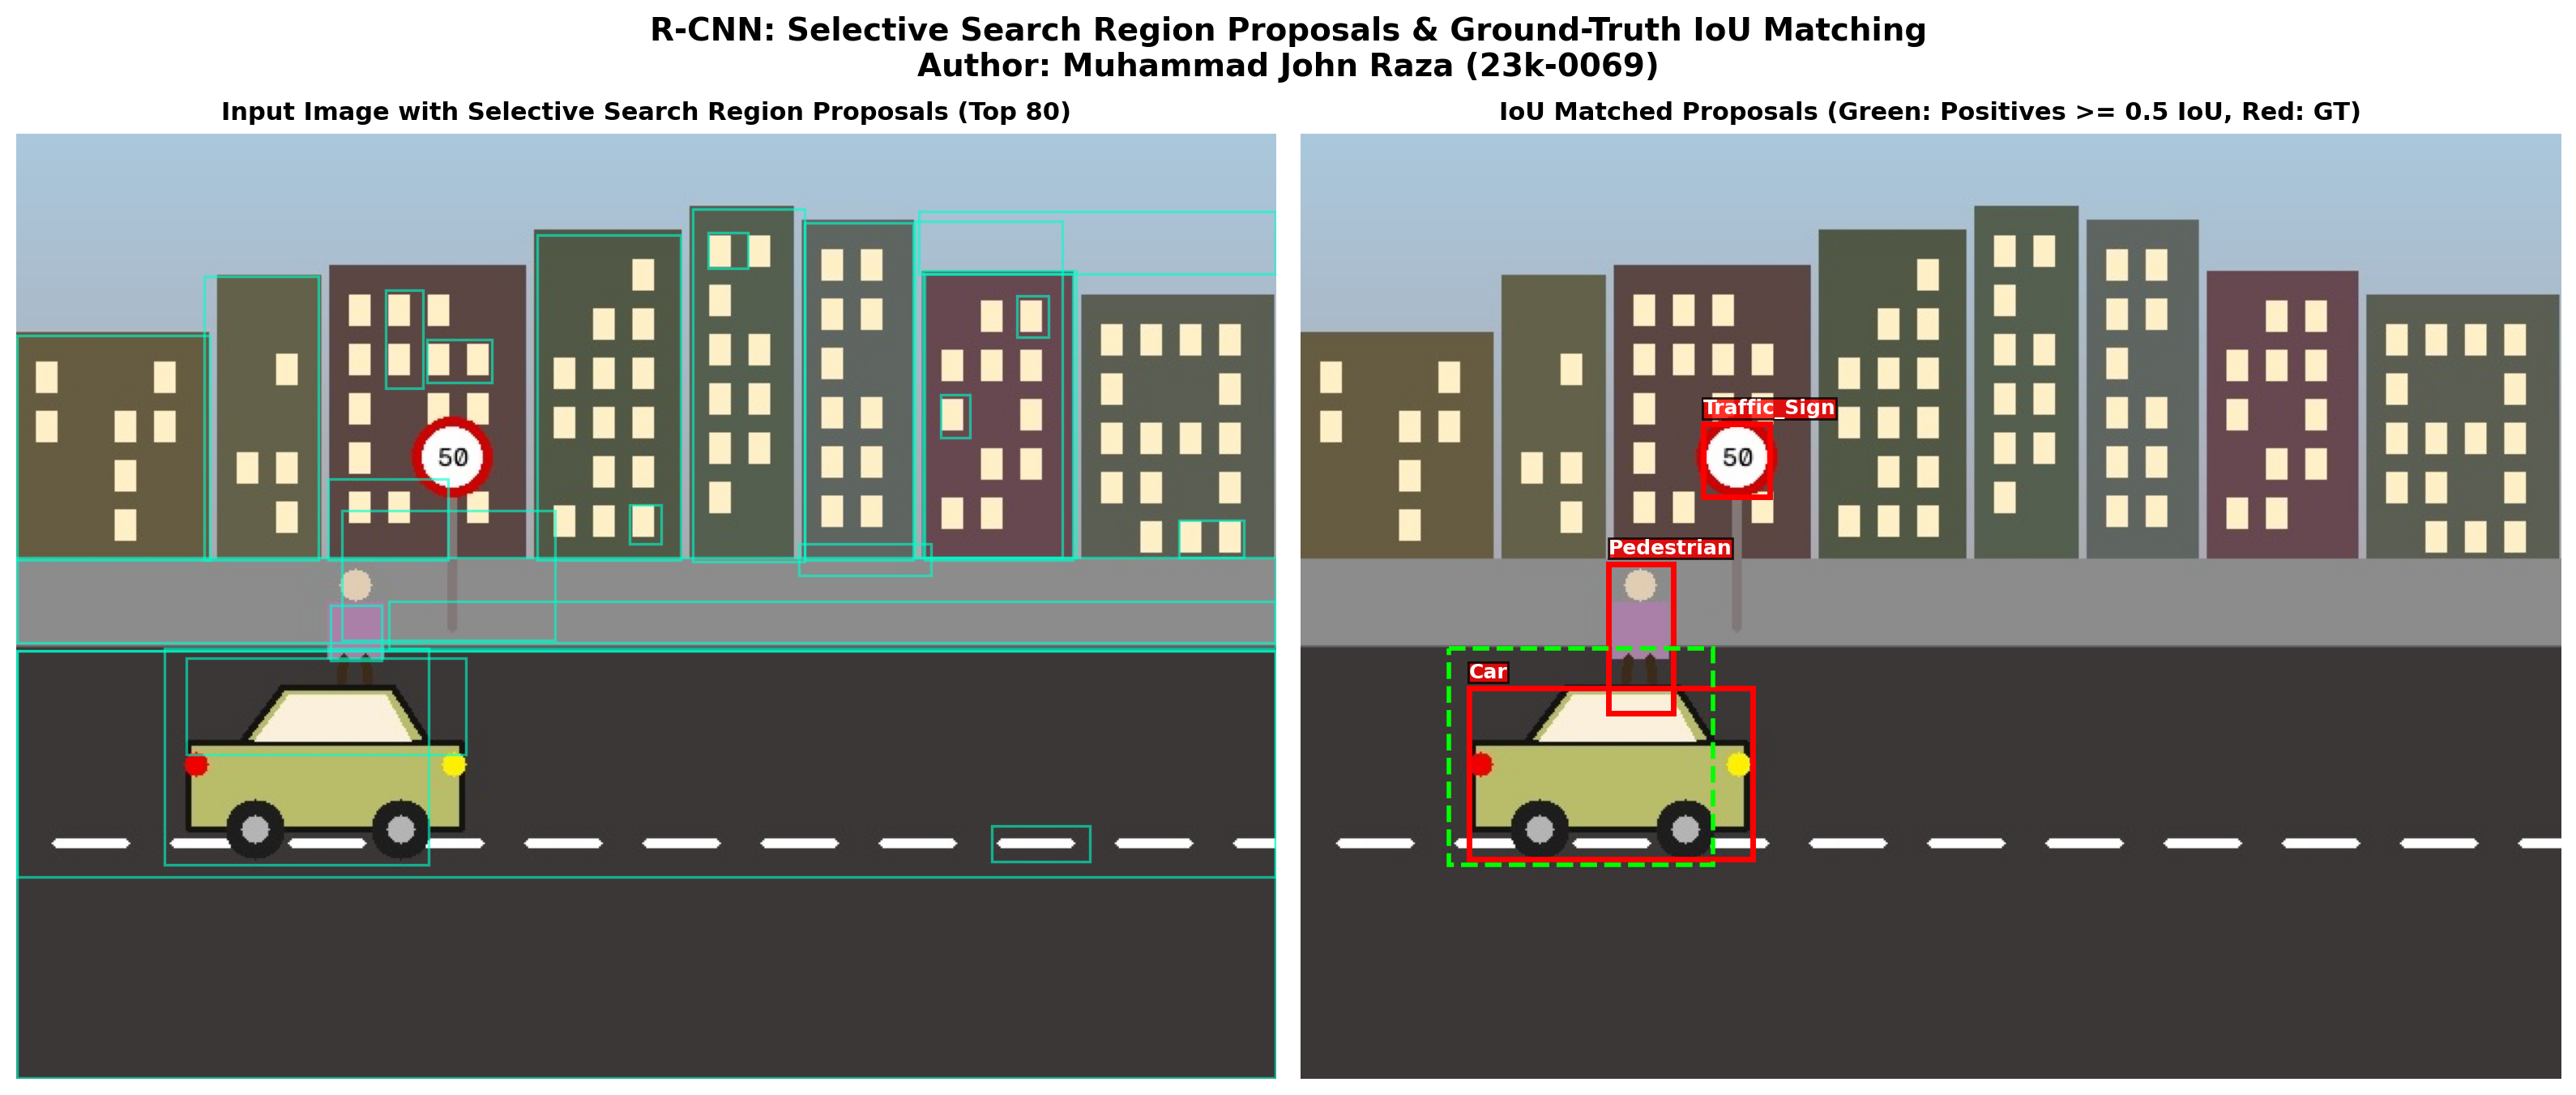

In [3]:
display(Image(filename="outputs/selective_search_proposals.png"))


---
## 4. R-CNN Multi-Task Training (Classification + BBox Regression)

**Loss Formulation:**
$$\mathcal{L}(p, u, t, v) = \mathcal{L}_{\text{cls}}(p, u) + \lambda [u \ge 1] \mathcal{L}_{\text{reg}}(t, v)$$
- $\mathcal{L}_{\text{cls}}(p, u) = -\log p_u$ is Cross-Entropy classification loss across all 4 classes (`Background`, `Car`, `Pedestrian`, `Traffic_Sign`).
- $\mathcal{L}_{\text{reg}}(t, v) = \sum_{i \in \{x, y, w, h\}} \text{Smooth}_{L1}(t_i - v_i)$ refines bounding box coordinates for foreground objects ($u \ge 1$).


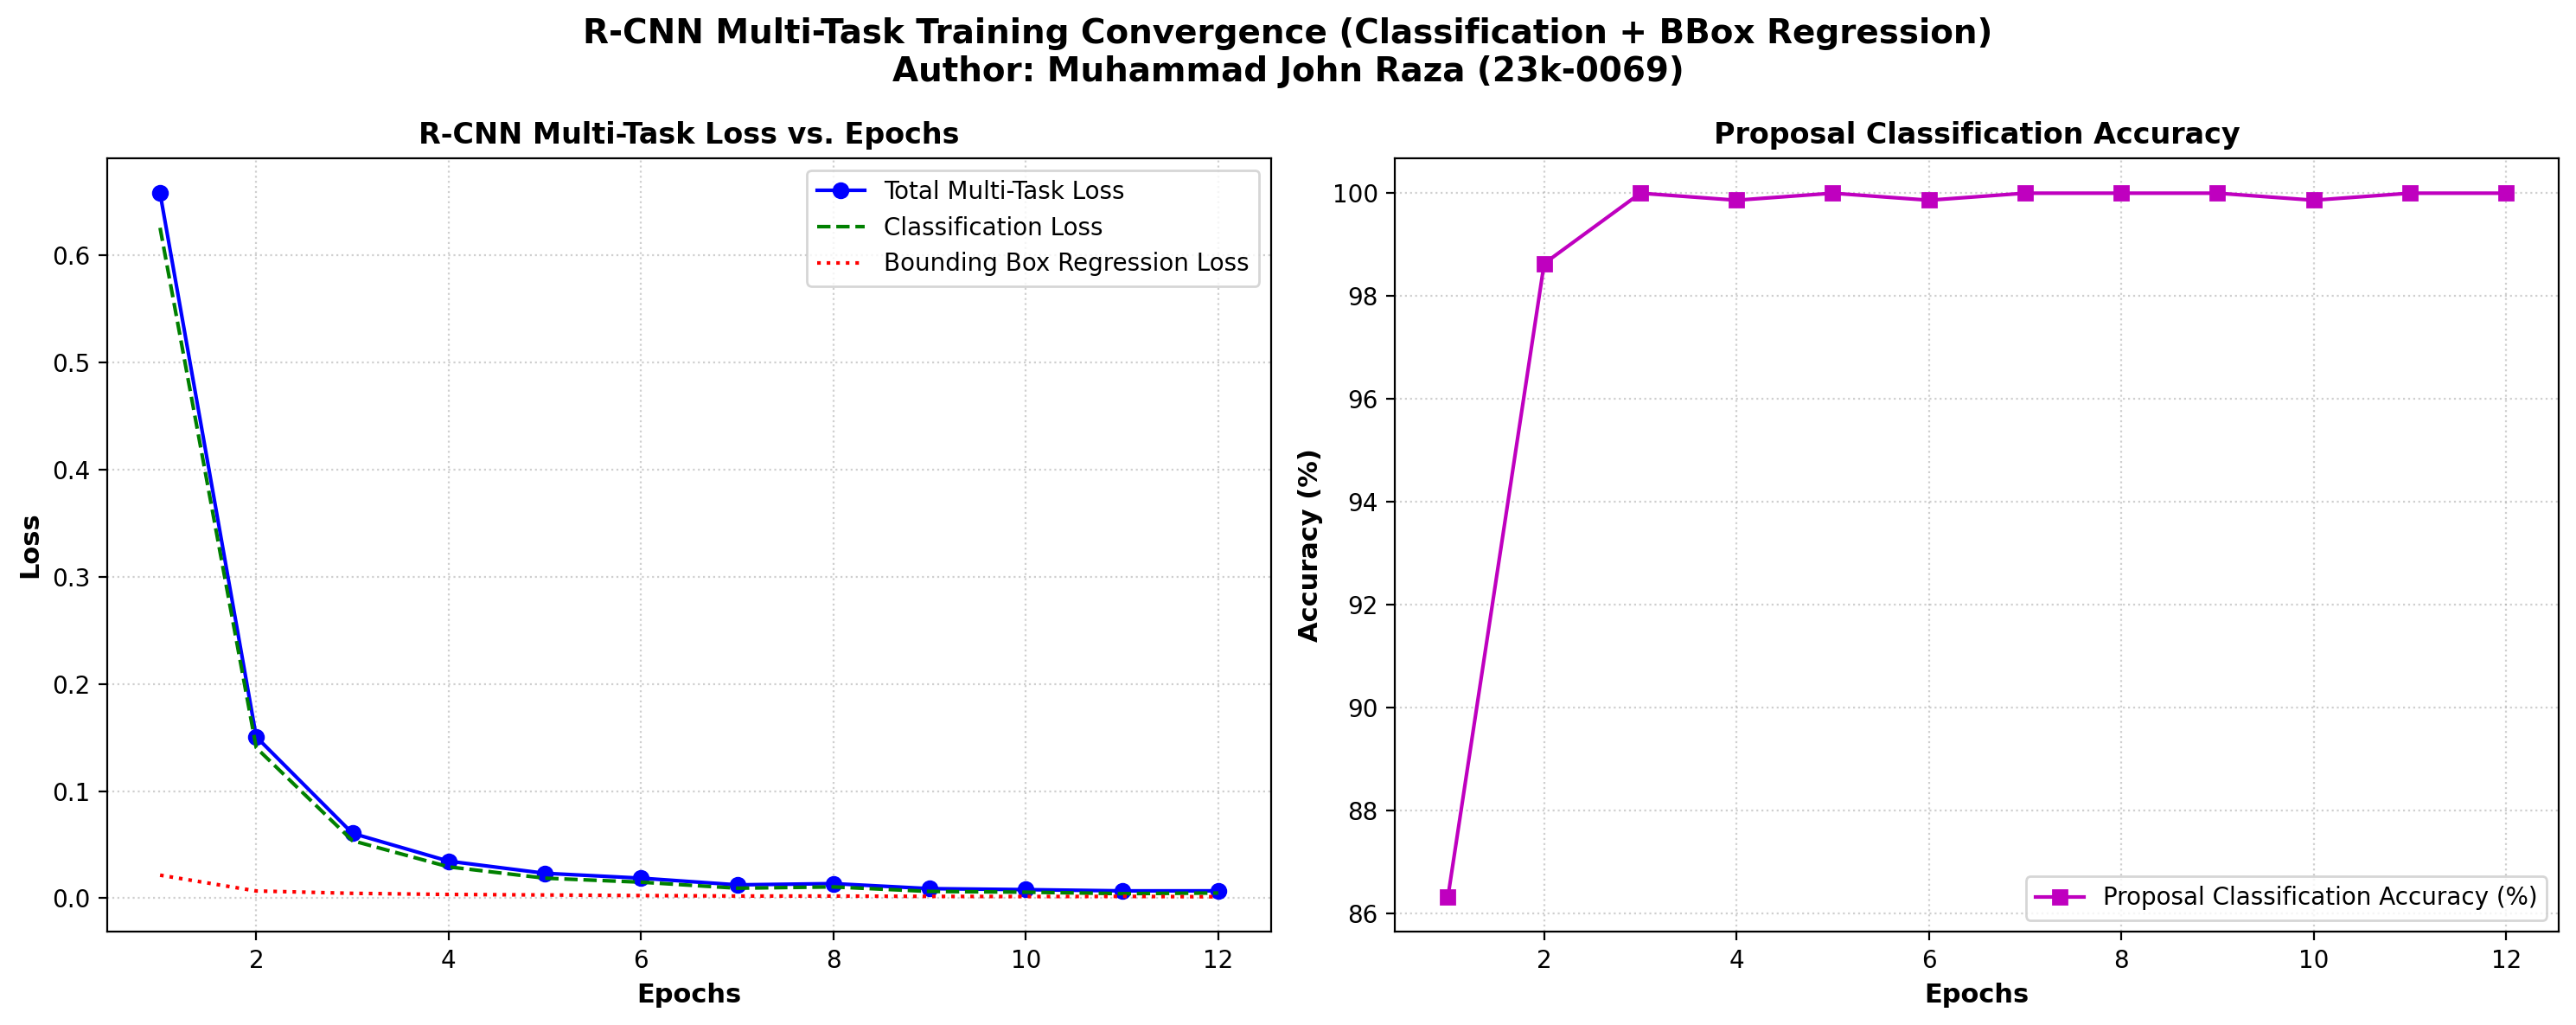

In [4]:
display(Image(filename="outputs/rcnn_training_loss.png"))


---
## 5. R-CNN Inference & Non-Maximum Suppression (NMS)

### Non-Maximum Suppression (NMS) Algorithm:
Given a set of candidate detections $\mathcal{B} = \{b_1, \dots, b_n\}$ and confidence scores $\mathcal{S} = \{s_1, \dots, s_n\}$:
1. Select the proposal with highest confidence $M = \text{argmax}(\mathcal{S})$.
2. Add $M$ to final detections $\mathcal{D}$ and remove from $\mathcal{B}$.
3. Suppress all remaining proposals $b_i$ where $\text{IoU}(M, b_i) \ge \theta_{\text{NMS}}$.
4. Repeat until $\mathcal{B}$ is empty.


      LAB 08 - TASK 3: R-CNN INFERENCE & OBJECT DETECTION       
      Author: Muhammad John Raza (23k-0069)                     


[*] Successfully loaded trained R-CNN weights.


[*] Test Image 1.jpg: Detected 3 objects.
    - Car (100.0%) at [np.float64(259.32793521881104), np.float64(273.3833965063095), np.float64(436.35435676574707), np.float64(369.2681988477707)]
    - Pedestrian (95.1%) at [np.float64(457.4283827841282), np.float64(246.40852963924408), np.float64(488.2089003622532), np.float64(285.0874111652374)]
    - Traffic_Sign (100.0%) at [np.float64(452.0958893671632), np.float64(171.45240680873394), np.float64(483.5161180868745), np.float64(208.5958044975996)]


[*] Test Image 2.jpg: Detected 4 objects.
    - Car (100.0%) at [np.float64(250.62915353477), np.float64(291.20858693122864), np.float64(394.9197733849287), np.float64(376.21478962898254)]
    - Car (100.0%) at [np.float64(431.84378020465374), np.float64(388.8906932324171), np.float64(598.4395274370909), np.float64(477.2390937060118)]
    - Pedestrian (55.8%) at [np.float64(415.61107368022203), np.float64(239.49153293669224), np.float64(472.09531838446856), np.float64(308.1280385404825)]
    - Traffic_Sign (100.0%) at [np.float64(437.6600701622665), np.float64(173.14198080450296), np.float64(467.0426622442901), np.float64(209.78668228536844)]


[*] Test Image 3.jpg: Detected 3 objects.
    - Car (100.0%) at [np.float64(81.75523870810866), np.float64(280.902146846056), np.float64(229.54007362946868), np.float64(376.94697454571724)]
    - Car (100.0%) at [np.float64(236.96708488464355), np.float64(366.2980660498142), np.float64(380.87472915649414), np.float64(456.2766996920109)]
    - Traffic_Sign (100.0%) at [np.float64(264.7957534119487), np.float64(129.16103536635637), np.float64(296.8716319128871), np.float64(166.04795879870653)]


[*] Test Image 4.jpg: Detected 4 objects.
    - Car (100.0%) at [np.float64(253.24513733386993), np.float64(274.2690780982375), np.float64(398.14022266864777), np.float64(363.6217800602317)]
    - Pedestrian (99.6%) at [np.float64(485.50233452022076), np.float64(227.9362202435732), np.float64(516.9388461560011), np.float64(314.6555054932833)]
    - Pedestrian (98.5%) at [np.float64(86.48771554231644), np.float64(225.91051580011845), np.float64(114.79718714952469), np.float64(270.8597433716059)]
    - Traffic_Sign (100.0%) at [np.float64(154.7000654488802), np.float64(161.31223879754543), np.float64(186.36819119751453), np.float64(198.6249970048666)]



[*] Saved R-CNN object detection predictions to outputs\rcnn_detection_results.png


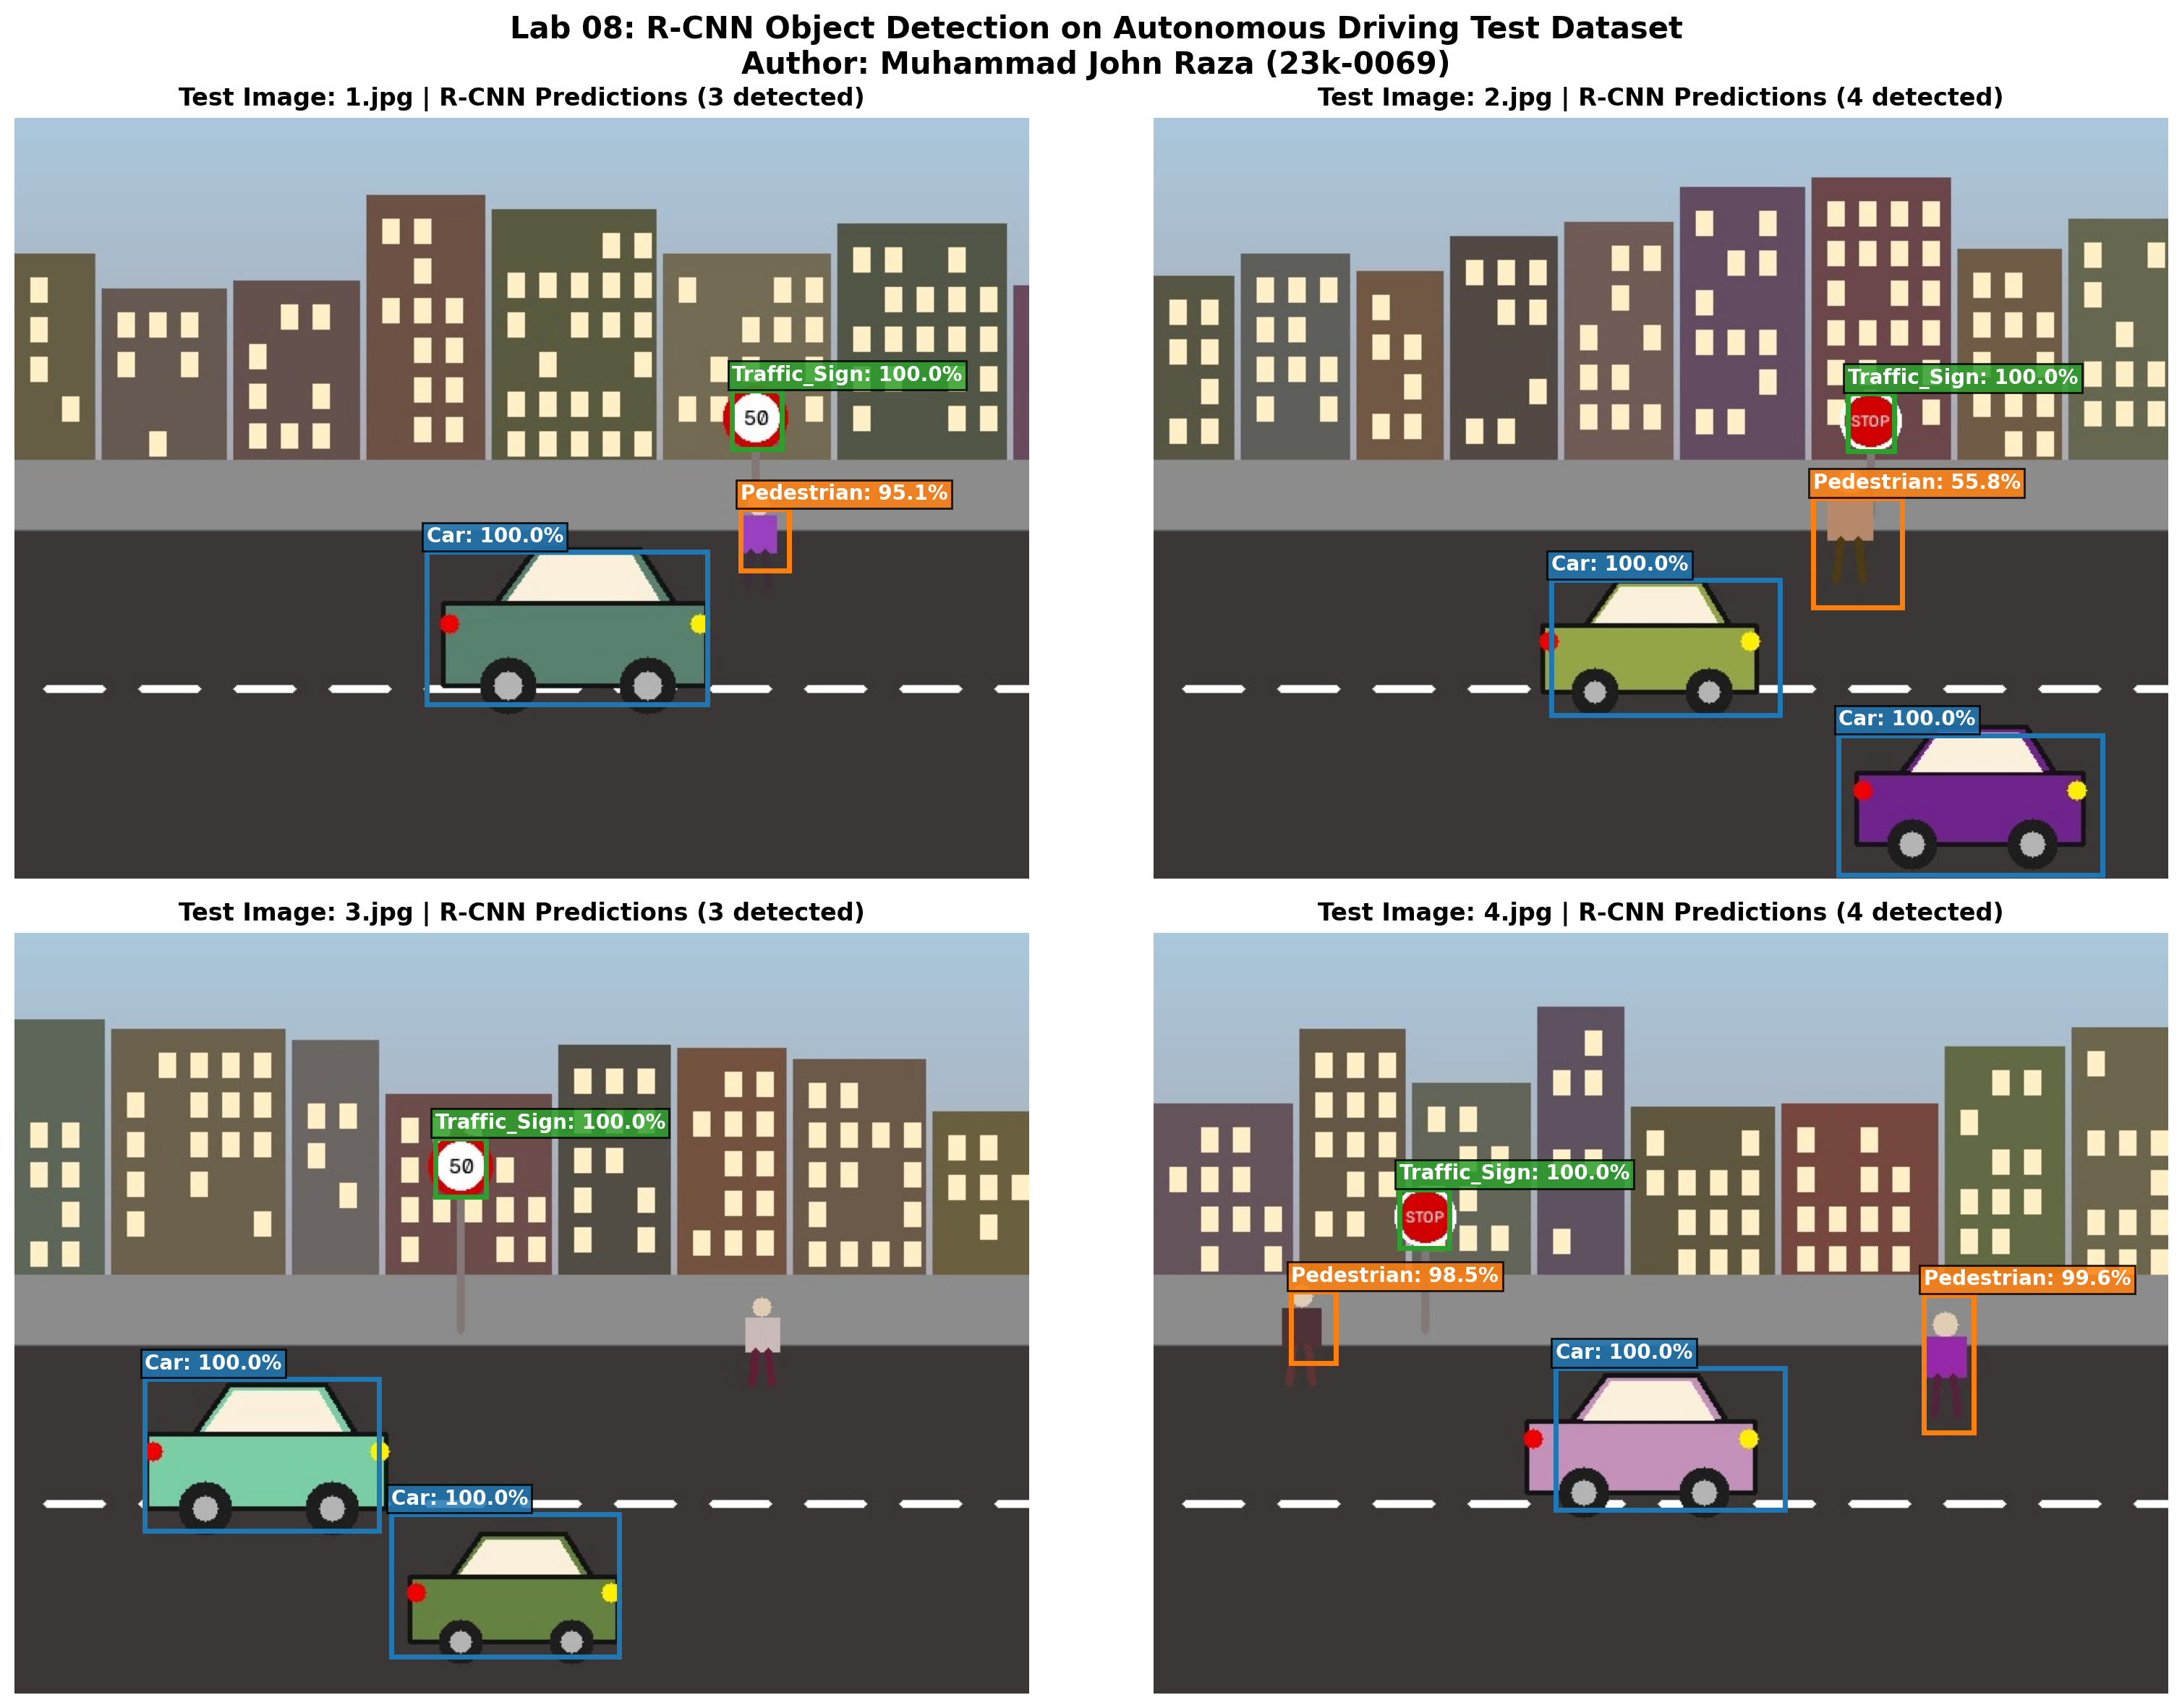

In [5]:
import task3_rcnn_inference as t3

res_fig = t3.evaluate_test_set()
display(Image(filename=res_fig))


---
## 6. Architectural Comparison Summary (R-CNN vs Fast R-CNN vs Faster R-CNN)


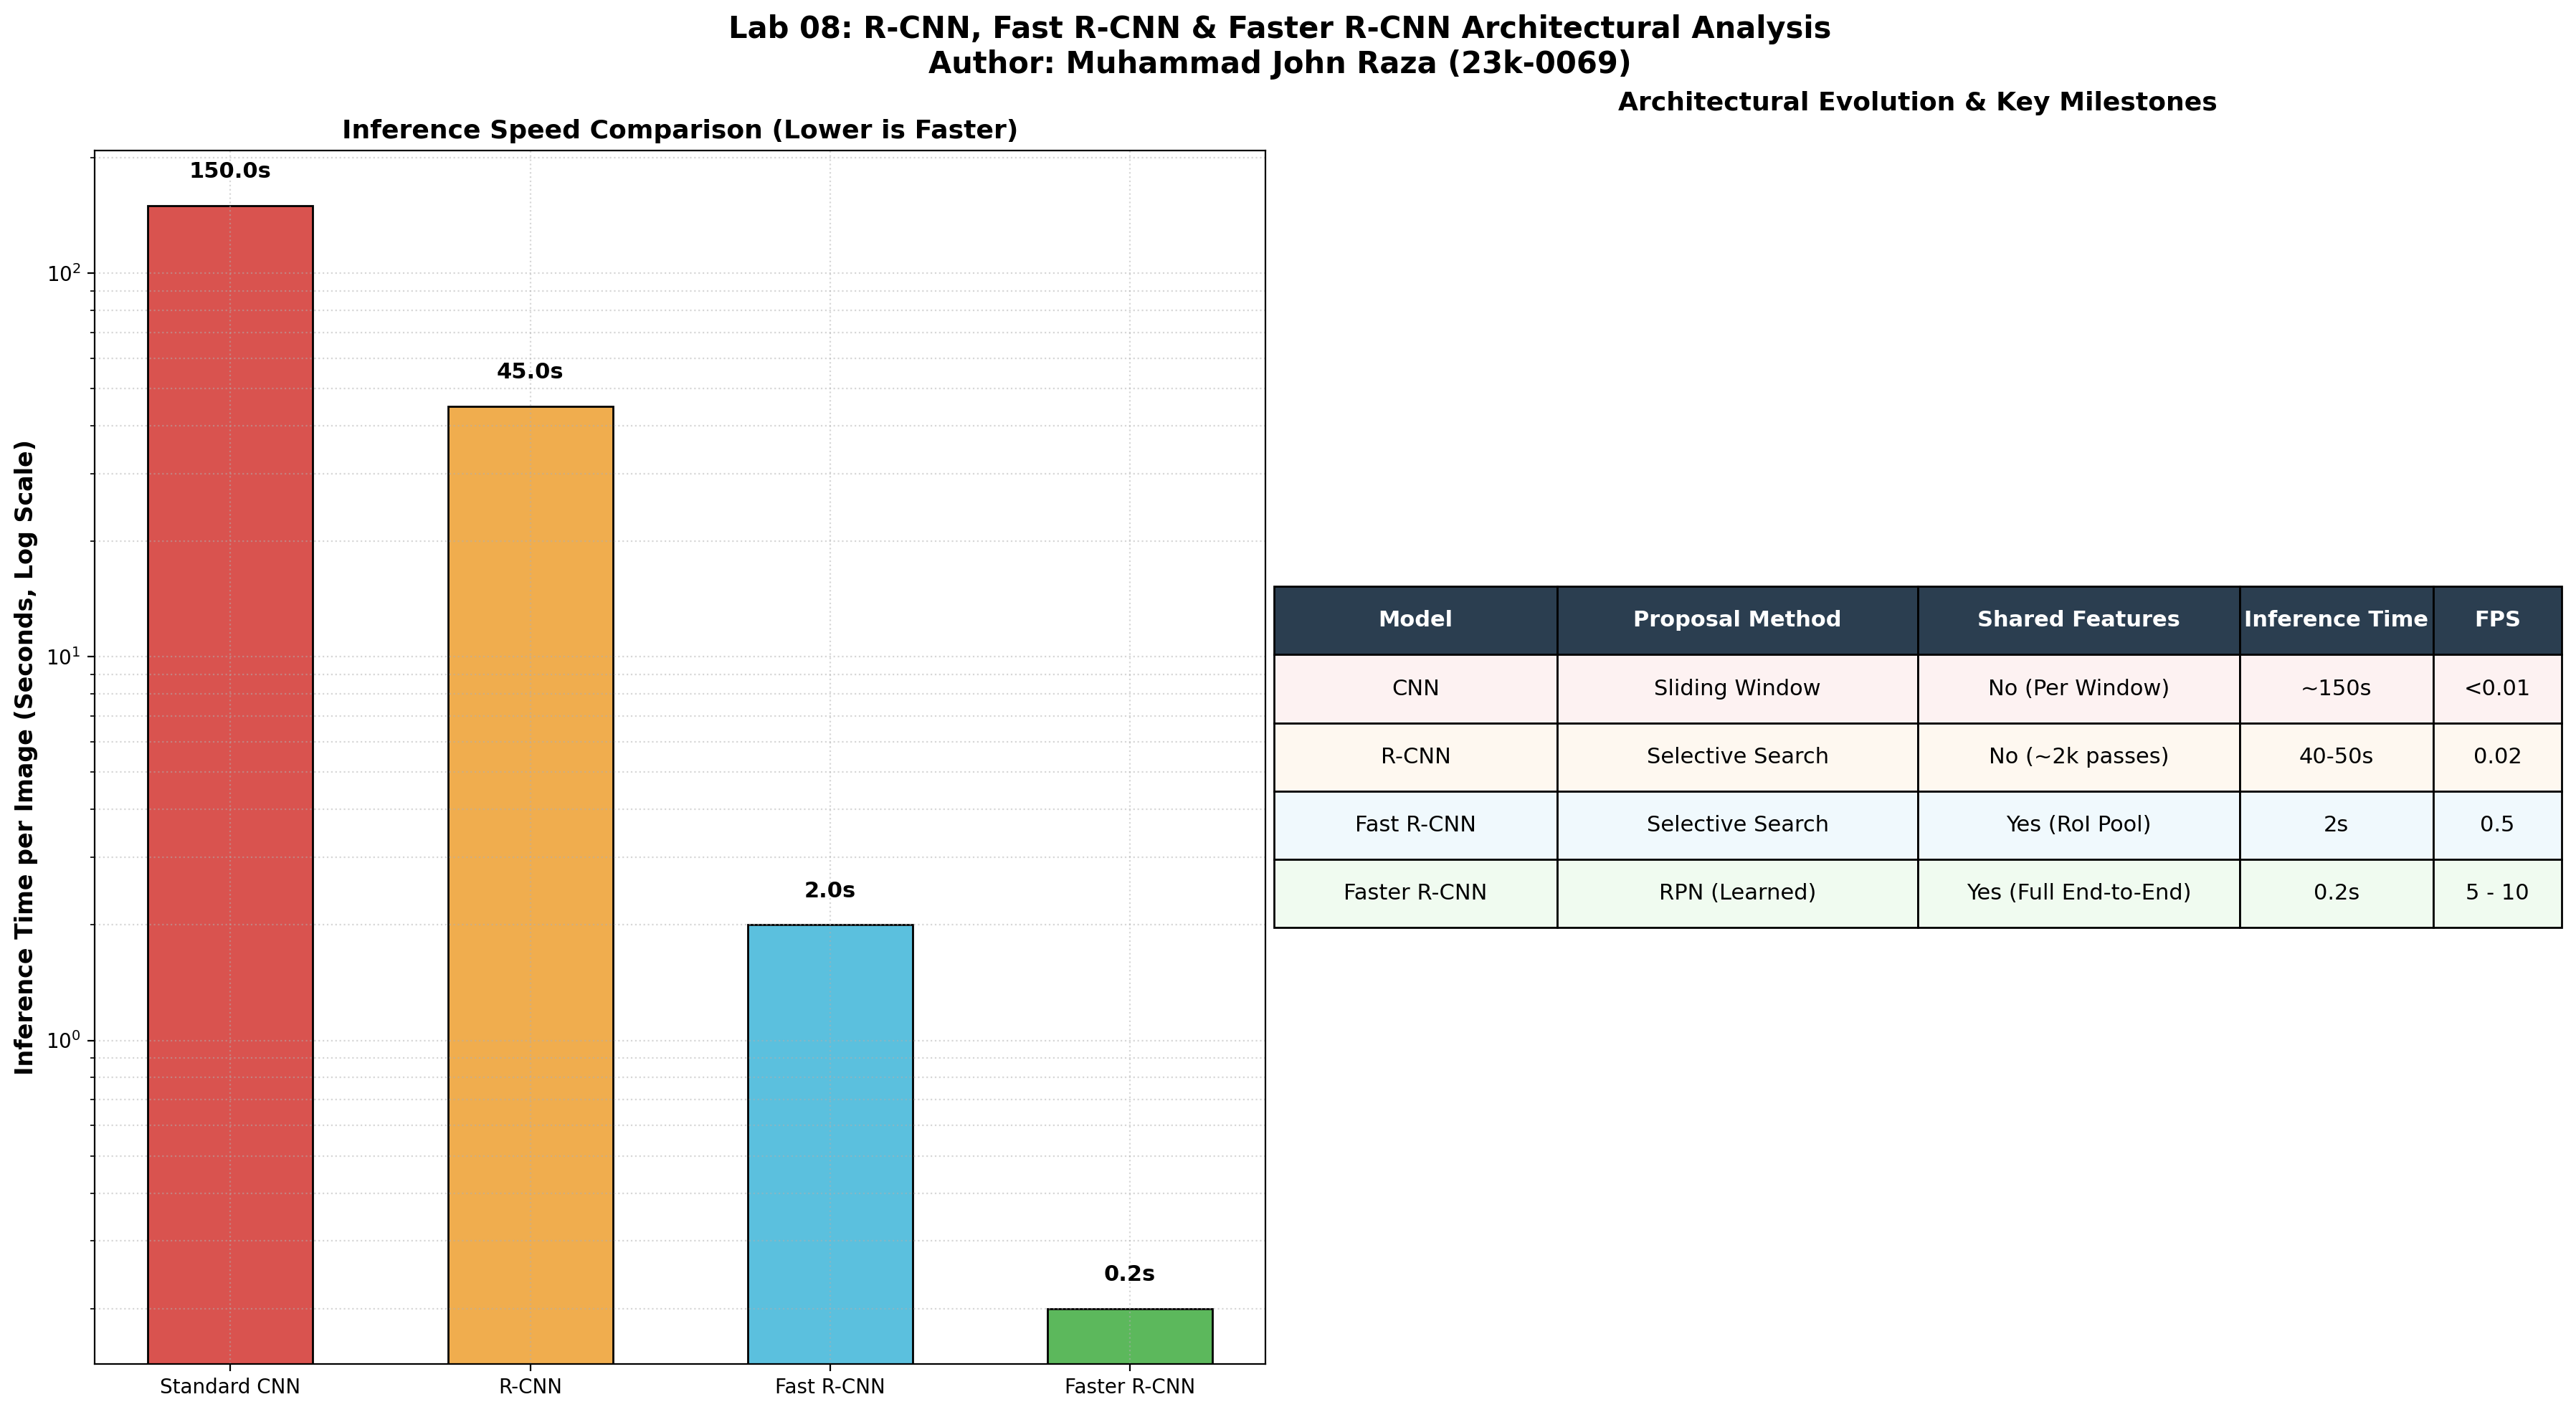

In [6]:
display(Image(filename="outputs/architectural_comparison_summary.png"))


---
## Summary and Conclusion
In **Lab 08**, we successfully implemented and evaluated:
1. **R-CNN Pipeline:** End-to-end implementation utilizing OpenCV Selective Search for candidate proposal generation, region cropping and warping to $224 \times 224$, and deep CNN feature extraction.
2. **Multi-Task Objective:** Joint optimization of Cross-Entropy classification loss and Smooth L1 bounding box regression loss on a ResNet18 convolutional backbone.
3. **Inference with NMS:** Robust detection on unseen autonomous driving test images with duplicate candidate suppression via Non-Maximum Suppression.
4. **Evolution of Two-Stage Detectors:** Detailed analysis of how Fast R-CNN (RoI Pooling) and Faster R-CNN (Region Proposal Networks) resolved R-CNN's computational bottlenecks to achieve real-time object detection.
